# Warming Stripes with MapReduce

The *Warming Stripes* are a very simple yet effective way to visualize long-term temperature trends and to raise awareness of the global warming problem and climate crisis. 
They were introduced by British climatologist Ed Hawkins, University of Reading; see [ShowYourStripes.info](https://showyourstripes.info/s/globe). The assignment given in this notebook uses the *Warming Stripes* as an illustrative example to introduce the MapReduce programming paradigm. It assumes a basic familiarity with MapReduce and moderate experiences in Python programming. The assignment serves as a beginner's example of implementing a mapper and a reducer. It is designed by H.M. Bücker and J. Schoder, Friedrich Schiller University Jena. (Version: January 31, 2022.)
   
## Assignment Overview and Data Sets   
   
This assignment uses MapReduce to analyze and visualize temperature trends in Germany based on data offered to everybody free of charge by Germany's National Meteorological Service (DWD).
The data set used in this assignement is accessible at [Weather Data](https://opendata.dwd.de/climate_environment/CDC/regional_averages_DE/monthly/air_temperature_mean/). Please note the corresponding [copyright information](https://www.dwd.de/EN/service/copyright/copyright_node.html) provided by DWD.
   
This excercise is meant as a proof-of-concept and primarily uses rather few data points. However, the underlying algorithm and structure are applicable to much larger data sets which are studied at the end of this assignment as a bonus task.  When working with weather data, we can imagine that large data sets can easily be accumulated by using temperature data from tiny IoT weather stations from all over the world, logging the air temperature every few minutes or even seconds.   
   
Imagine that there are 193 member states as part of the United Nations. In each of these states we have, say, 100 weather stations distributed across the countryside which send their temperature data as a 32-bit single-precision floating-point number to a central server every minute. Thus, in total, we would accumulate

$$
193 \text{ countries} 
\cdot 100 \frac{\text{weather stations}}{\text{country}} 
\cdot 365 \frac{\text{days}}{\text{weather station}} 
\cdot  24 \frac{\text{hours}}{\text{day}} 
\cdot  60 \frac{\text{minutes}}{\text{hour}} 
\cdot   4 \frac{\text{Bytes}}{\text{year}}.
$$   
This results in 40,576,320,000 Bytes per year or about 40 GB per year.   
The problem size, of course, increases if we use smaller logging intervals or more weather stations. So, if we prefer a reasonably fast exectution time to compute the annual average temperature values for large data sets, we will eventually need to take advantage of some kind of parallelism.   
   
One attempt to employ parallelism is the MapReduce framework. The Federal Republic of Germany comprises 16 constituent states. The data consist of monthly average temperature values of different states over several decades. These values are distributed across different files storing the average temperature of one month for every year in every state. The task is to compute the annual average temperatures in Germany for all years.

An algorithm for the solution of this averaging problem is straightforwardly implemented in a general-purpose programming language. However, the MapReduce progamming model requires to reformulate algorithms in terms of mappers and reducers. The goal of this exercise is to start learning reformulating algorithms in the MapReduce progamming model.

# Preparation 1: Load Dependencies

For the first tests we just need to load the numpy and the matplotlib libraries.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Preparation 2: Visualize the Verification Result

At first, we get the reference data from [DWD](https://opendata.dwd.de/climate_environment/CDC/regional_averages_DE/annual/air_temperature_mean/regional_averages_tm_year.txt) and store it, e.g., in a folder called ```./Data/ctl/```.

Then, we plot the already averaged temperature values for the sake of a reference solution.




In [ ]:
data = np.loadtxt("Data/ctl/regional_averages_tm_year.txt", skiprows=2, delimiter=";", usecols = (0,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18))
#temps_berlin_brandenburg= data[:,1]
temps = data[:,17]

tmin = temps.min() 
tmax = temps.max() 
tavg = np.average(temps)

print("Maximum Temperature: " + str(tmax))
print("Minimum Temperature: " + str(tmin))
print("Average Temperature: " + str(tavg))

## stack data to be able to plot them with imshow
stacked_temps = np.stack((temps, temps))

Maximum Temperature: 10.45
Minimum Temperature: 6.63
Average Temperature: 8.356258992805754


### Plotting Procedure

The actual plotting procedure takes the list of average temperatures of each year as a first argument. 
The second argument specifies a method for visualization with the following meaning:   

- If the parameter ```method``` is equal to 0, the color grading ranges from the average temperature of the whole time span by ± 1.5 degree Celsius.

- If the parameter ```method``` is equal to 1, the color grading ranges from the overall minimum temperature to the overall maximum temperature.

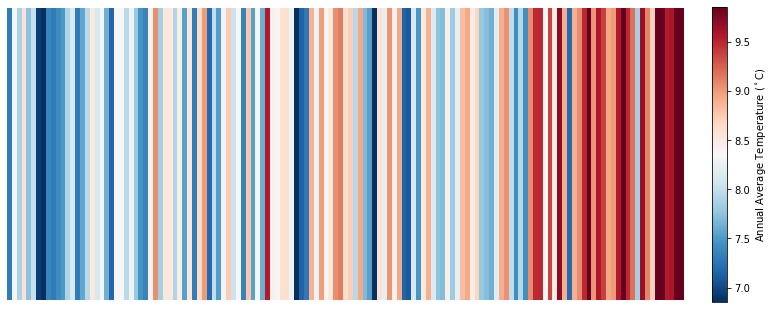

In [ ]:
def plot_warming_stripes(stacked_temps, method):
    ###############
    plt.figure(figsize=(10,20))
    tavg = np.average(temps)
    if method == 0:
        #scale on average value +- 1.5 degree celcius
        vmin = tavg - 1.5
        vmax = tavg + 1.5
        img = plt.imshow(stacked_temps, cmap='RdBu_r', aspect=30, vmin=vmin, vmax=vmax)
    else: 
        #automatically scale on max and min temperature value   
        img = plt.imshow(stacked_temps, cmap='RdBu_r', aspect=30)
    
    plt.gca().set_axis_off()
    plt.subplots_adjust(top = 1, bottom = 0, right = 1, left = 0, hspace = 0, wspace = 0)
    plt.margins(0,0)
    plt.gca().xaxis.set_major_locator(plt.NullLocator())
    plt.gca().yaxis.set_major_locator(plt.NullLocator())
    plt.colorbar(img,fraction=0.0205, pad=0.04, label='Annual Average Temperature ($^\circ$C)')
    plt.savefig("stripes.png", bbox_inches = 'tight', pad_inches = 0, dpi=400)

plot_warming_stripes(stacked_temps, 0)

# Assignment Tasks: 

# Task 1: Data Aquisition and Preparation

### Download the actual [DWD data set](https://opendata.dwd.de/climate_environment/CDC/regional_averages_DE/monthly/air_temperature_mean/) to the folder ```./Data/``` and inspect the files.   
There are 12 input files, one for each month. Every file contains a table with one row per year. In every row, the first column denotes the year, the second column the month of the year, and the rest of the columns give us average temperature values of different federal states in Germany of the particular month. 

There are several alternatives to the DWD data including the following: 
   - https://www.ncdc.noaa.gov/cdo-web/datasets   
   - https://www.kaggle.com/berkeleyearth/climate-change-earth-surface-temperature-data   
   - http://berkeleyearth.org/archive/analysis-code   



# Task 2: Recreate the Warming Stripes with Hadoop Streaming
      

**Clean data**

In [11]:
import glob
import os

data = []

for file in glob.glob("./Data/raw/*"):
    data.append(np.loadtxt(file, skiprows=2, delimiter=";", usecols = (0,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18)))

    if not os.path.exists('./Data/cleaned'):
        os.makedirs('./Data/cleaned')

    np.savetxt('./Data/cleaned/' + os.path.basename(file), data[-1], delimiter='\t', fmt='%s', comments='')

**Map data**